# 03 · Reward shaping and learning stability: TD3 vs DDPG

How does the reward the agent *trains on* change learning stability, and does it change how the finished policy copes with failures? We train **TD3 and DDPG** with identical hyperparameters on five reward variants (`default`, `dist_only`, `sparse`, `progress`, `scaled_x10`) across 5 seeds, then stress-test every solved policy.

Everything is judged on the **unshaped task**: summed negative distance to the target (higher is better) and success rate (fingertip within 5 cm at the end). Shaped training returns are never compared, because each variant uses a different reward scale.

The full sweep takes hours, so this notebook does not run it: it loads the committed results in `plots/`. To reproduce, run `python scripts/sweep.py`, `python scripts/sweep_analysis.py`, `python scripts/shaping_robustness.py`. Set `DFC_QUICK=1` for a tiny smoke-test sweep.

In [1]:
import os
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "envs" / "stress_wrappers.py").exists())
sys.path.insert(0, str(ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

QUICK = os.environ.get("DFC_QUICK", "0") == "1"  # DFC_QUICK=1 -> tiny sweep, for smoke-testing only
PLOTS = ROOT / "plots" / ("quick" if QUICK else "")
PLOTS.mkdir(parents=True, exist_ok=True)
print("project root :", ROOT.name)
print("quick mode   :", QUICK)

project root : deep-feedback-control
quick mode   : False


## Load results

In [2]:
from scripts.train import load_config
from scripts.sweep import load_sweep_config, quick_config, run_sweep
from scripts.sweep_analysis import plot_learning_curves, plot_metric_comparison, write_sweep_outputs
from scripts.shaping_robustness import plot_robustness, run_robustness

train_cfg = load_config()
sweep_cfg = load_sweep_config()
threshold = sweep_cfg["solve_threshold"]

if QUICK:
    sweep_cfg = quick_config(sweep_cfg)           # 2 algos x 2 variants x 1 seed, ~800 steps
    run_sweep(sweep_cfg, train_cfg, log=print)    # resumable
    write_sweep_outputs(sweep_cfg["runs_dir"], PLOTS, threshold, sweep_cfg["learning_starts"])
    try:
        run_robustness(sweep_cfg, train_cfg, PLOTS, workers=1)
    except ValueError as err:                     # quick policies rarely reach the solve threshold
        print("robustness skipped in quick mode:", err)
else:
    needed = ["sweep_eval_curves.csv", "sweep_summary.csv", "sweep_random_baseline.json"]
    missing = [n for n in needed if not (PLOTS / n).exists()]
    assert not missing, f"missing {missing} in plots/: run `python scripts/sweep.py` then `python scripts/sweep_analysis.py`"

curves = pd.read_csv(PLOTS / "sweep_eval_curves.csv")
summary = pd.read_csv(PLOTS / "sweep_summary.csv")
random_baseline = json.loads((PLOTS / "sweep_random_baseline.json").read_text())["mean_distance_return"]
print(f"{curves.groupby(['algo', 'variant', 'seed']).ngroups} runs loaded; random policy = {random_baseline:.2f}")

50 runs loaded; random policy = -10.32


## Stability table
Means over seeds with 95% bootstrap CIs (crude with 5 seeds). `n_reached` = seeds that reached the solve threshold.

In [3]:
cols = ["algo", "variant", "n_seeds", "n_reached", "final_return_mean", "final_return_lo", "final_return_hi",
        "final_success_mean", "auc_mean", "steps_to_threshold_mean", "max_drawdown_mean"]
display(summary[cols].round(3))

,algo,variant,n_seeds,n_reached,final_return_mean,final_return_lo,final_return_hi,final_success_mean,auc_mean,steps_to_threshold_mean,max_drawdown_mean
0,ddpg,default,5,5,-3.727,-3.879,-3.586,0.787,-5.328,26000.0,0.921
1,ddpg,dist_only,5,5,-3.118,-3.582,-2.517,0.680,-5.146,21600.0,1.343
2,ddpg,progress,5,0,-8.224,-8.989,-7.422,0.053,-8.212,NaN,4.128
3,ddpg,scaled_x10,5,5,-3.892,-4.180,-3.648,0.767,-5.531,26400.0,0.842
4,ddpg,sparse,5,5,-3.025,-3.430,-2.710,0.833,-5.301,23200.0,1.432
5,td3,default,5,5,-3.360,-3.483,-3.238,0.967,-5.315,17600.0,0.568
6,td3,dist_only,5,5,-2.097,-2.465,-1.888,0.973,-4.280,14800.0,0.410
7,td3,progress,5,0,-5.680,-6.104,-5.321,0.627,-6.501,NaN,1.706
8,td3,scaled_x10,5,5,-3.776,-3.932,-3.621,0.900,-5.618,18800.0,0.562
9,td3,sparse,5,5,-2.423,-2.604,-2.220,0.953,-5.124,22400.0,1.102


## Learning curves
Thin lines are individual seeds, thick lines the mean, bands the 95% bootstrap CI.

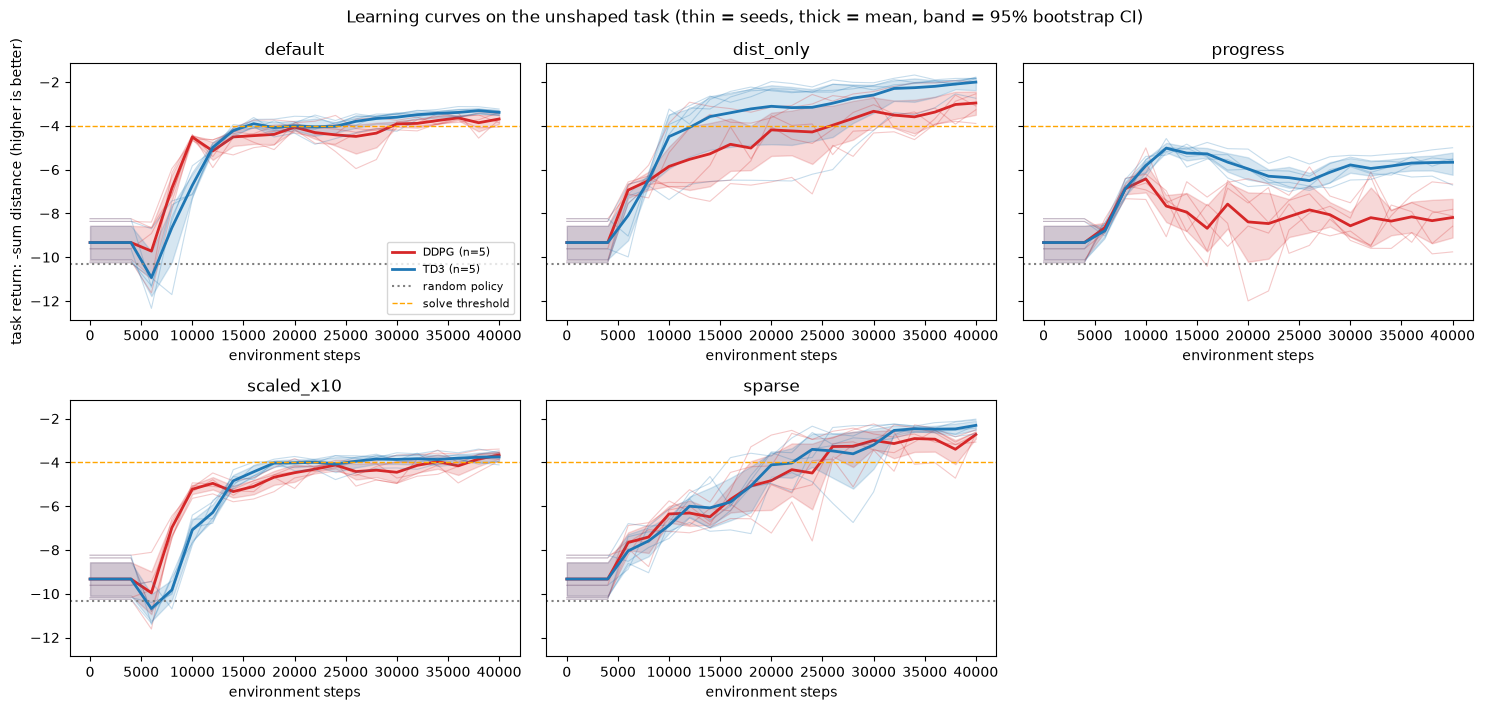

In [4]:
fig = plot_learning_curves(curves, random_baseline, threshold)
plt.show()

## Metric comparison

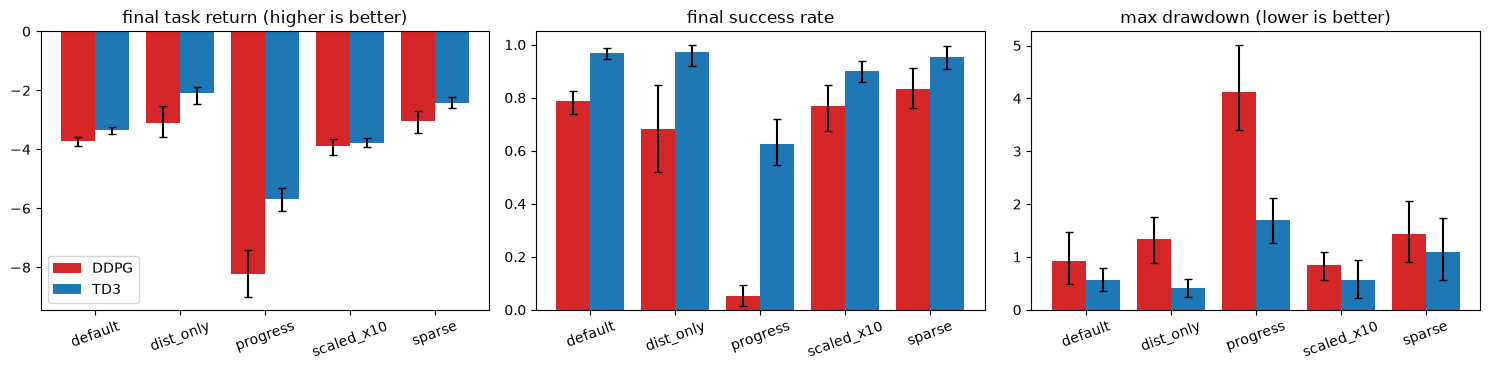

,variant,metric,diff_mean,diff_lo,diff_hi,n_td3,n_ddpg
0,default,final_return,0.366,0.181,0.557,5,5
1,dist_only,final_return,1.021,0.349,1.595,5,5
2,progress,final_return,2.544,1.648,3.391,5,5
3,scaled_x10,final_return,0.115,-0.183,0.448,5,5
4,sparse,final_return,0.602,0.222,1.044,5,5


In [5]:
fig = plot_metric_comparison(summary)
plt.show()
diffs_path = PLOTS / "sweep_algo_differences.csv"
if diffs_path.exists():
    display(pd.read_csv(diffs_path).round(3))

## Robustness of the solved policies
Each solved final policy is stress-tested with a reduced IPQC battery. Policies that never reached the solve threshold are excluded (see the eligibility table), never scored.

,algo,variant,n_policies,n_eligible
0,ddpg,default,5,2
1,ddpg,dist_only,5,5
2,ddpg,progress,5,0
3,ddpg,scaled_x10,5,4
4,ddpg,sparse,5,4
5,td3,default,5,5
6,td3,dist_only,5,5
7,td3,progress,5,0
8,td3,scaled_x10,5,2
9,td3,sparse,5,5


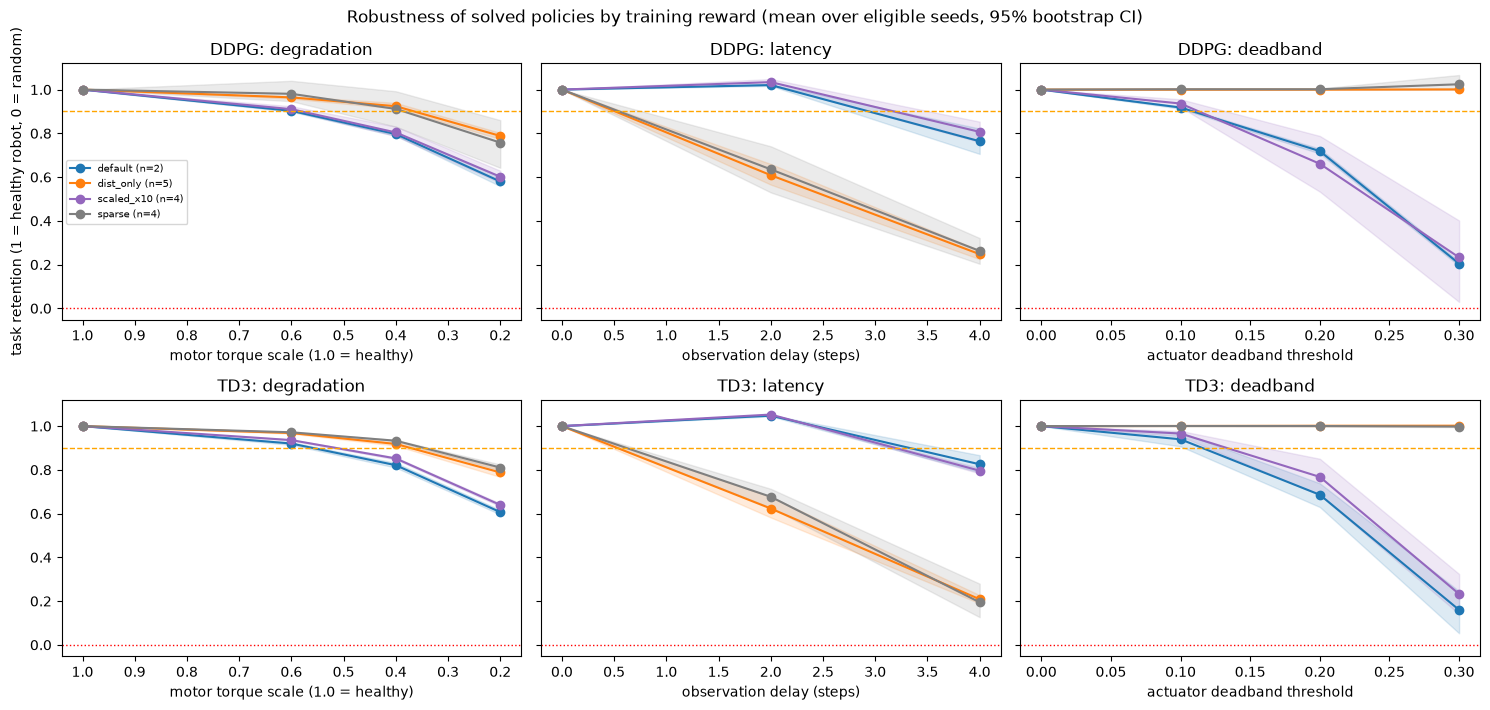

,algo,variant,stress_type,boundary_median,boundary_mean,n_eligible,n_not_reached
0,ddpg,default,deadband,0.1,0.10,2,0
1,ddpg,default,degradation,0.8,0.80,2,0
2,ddpg,default,latency,2.0,2.00,2,0
3,ddpg,dist_only,deadband,0.3,0.30,5,5
4,ddpg,dist_only,degradation,0.4,0.40,5,0
5,ddpg,dist_only,latency,0.0,0.00,5,0
6,ddpg,scaled_x10,deadband,0.1,0.10,4,0
7,ddpg,scaled_x10,degradation,0.6,0.60,4,0
8,ddpg,scaled_x10,latency,2.0,2.00,4,0
9,ddpg,sparse,deadband,0.3,0.30,4,4


In [6]:
rob_paths = {n: PLOTS / n for n in ["shaping_eligibility.csv", "shaping_robustness_summary.csv", "shaping_boundaries_summary.csv"]}
if all(p.exists() for p in rob_paths.values()):
    display(pd.read_csv(rob_paths["shaping_eligibility.csv"]))
    rob_summary = pd.read_csv(rob_paths["shaping_robustness_summary.csv"])
    if rob_summary.empty:
        print("no policy reached the solve threshold, so there is nothing to compare")
    else:
        plot_robustness(rob_summary)
        plt.show()
        display(pd.read_csv(rob_paths["shaping_boundaries_summary.csv"]).round(3))
else:
    print("no robustness results yet: run `python scripts/shaping_robustness.py`")

## Findings

Five seeds and 40,000 steps per run, all on `Reacher-v4`; every number below is read from the tables and CSVs above.

**Learning (unshaped task)**

- TD3 reaches a better final task return than DDPG for four of the five reward variants. TD3 minus DDPG, with a 95% bootstrap CI: `default` +0.37 [0.18, 0.56], `dist_only` +1.02 [0.35, 1.60], `sparse` +0.60 [0.22, 1.04], `progress` +2.54 [1.65, 3.39], and `scaled_x10` +0.12 [-0.18, 0.45] (not distinguishable). TD3 also reaches the solve threshold sooner (`default`: 17,600 vs 26,000 steps) and has a higher final success rate (`default`: 0.97 vs 0.79).
- TD3 also has the lower maximum drawdown (measured after learning starts) in every variant that solved the task: `default` 0.57 vs 0.92, `scaled_x10` 0.56 vs 0.84, `dist_only` 0.41 vs 1.34, `sparse` 1.10 vs 1.43. Only `dist_only` is clear-cut; the other CIs overlap.
- `dist_only` and `sparse` give the best final task returns (TD3: -2.10 and -2.42, against -3.36 for `default`). That is partly by construction: the task metric ignores control cost and these two variants pay none. At nominal their policies spend a control cost of about -28 to -43, against under -1 for `default`, so they drive the actuators near their limits. Under the default reward they would score far worse.
- `sparse` did not fail: all 10 runs reached the solve threshold. (I had expected it might.)
- `progress` failed even after I fixed an implementation bug (an earlier version credited each action with the previous action's movement, because `Reacher-v4` measures distance before the action): 0 of 10 runs reached the threshold; TD3 final -5.68 (success 0.63), DDPG -8.22 (success 0.05). Its policies use very small actions. Why it fails is untested; it has no term for being close to the target, only for getting closer.
- `scaled_x10` changes little: TD3 -3.78 against -3.36 (slightly worse; the CIs do not overlap), DDPG -3.89 against -3.73.

**Robustness of solved policies**

- The pattern replicates in TD3 and DDPG. `dist_only` and `sparse` keep retention of about 1.00 up to a deadband of 0.3 and 0.76-0.81 at 20% torque, but collapse under observation latency (0.61-0.68 at 2 steps, 0.19-0.26 at 4 steps). `default` and `scaled_x10` are the reverse: 1.02-1.05 at 2 steps of delay and 0.76-0.83 at 4, but 0.66-0.77 at deadband 0.2 and 0.16-0.23 at 0.3. Retention above 1 means a 2-step delay marginally improves those policies on the task metric, so a policy's own nominal is not a ceiling.
- Untested hypothesis: near-saturated actuation is unaffected by a dead zone but overshoots when observations are stale.
- Caveat: a policy is only stress-tested if its own nominal return is at least -4 on the robustness episodes. That leaves DDPG `default` 2 of 5, TD3 `scaled_x10` 2 of 5 and `progress` 0 of 10, and the eligible sets differ across variants, so the comparison carries a selection effect.
